# HW3 Grid World — PyTorch 원본 코드를 처음부터 직접 작성하는 실습형 Notebook

**목표:** 이전에 제공한 `gridworld-hw3-pytorch-verified-lecture2-3.zip`과 **동일한** 핵심 소스코드(`main.py`, `pyproject.toml`, `src/`, `tests/`, `.gitignore`)를 빈 폴더에서 재구성합니다. 본 Notebook은 단순히 알고리즘을 실행하는 것이 아니라, **왜 그 순서로 코드를 작성하고 각 줄이 무엇을 하는지 이해하면서 타이핑하는 교재**입니다.

**사용법:** 위에서 아래로 진행합니다. `%%writefile` 아래의 완성 코드는 정답이자 타이핑 대상이므로, 가능하면 보면서 **직접 입력**하세요. 각 파일을 저장한 후 바로 아래의 확인 셀을 실행하세요. 마지막에는 원본 ZIP과 코드 내용이 **파일 단위 SHA-256 해시까지 일치하는지** 검증합니다.

이 Notebook은 원본을 덮어쓰지 않고 현재 위치에 `handwritten_gridworld_hw3/`라는 **별도 연습 프로젝트**를 생성합니다. 처음에는 소규모 에피소드로 확인하고, 50,000에피소드 실험은 맨 마지막에서 명시적으로 선택합니다.

**완성 후 할 수 있는 일:** 1-1/2-1 코드 제출, 1-2/2-2 가치함수 출력·그림 저장, 2-3 MC·TD(0) 비교 설명, 단위 테스트, GitHub 버전 관리.


## 0. 과제의 조건과 출처부터 확정하기

이 구현에 사용한 자료는 다음 세 가지입니다.

- **`HW3.pdf` p.1–2:** MC와 TD(0)를 4×4 격자에서 구현하고 값을 출력하며 차이를 설명하라는 과제, 시작 `S0`, 종료 `S15`, 무작위 행동, 보상 -1, 할인율 1, 반복 50,000.
- **`[커넥티드카ML]Lecture3_Modelfree_Prediction.pdf` p.8–12, 14–15:** Every-Visit MC는 *모든 방문*을 평균내고 에피소드 종료 후 업데이트, TD(0)는 전이 직후 업데이트하며 **학습률 0.01** 사용.
- **`[커넥티드카ML]Lecture2_DP.pdf` p.11, 14:** 격자 바깥을 향한 행동은 원래 상태에 머무르며 -1 보상을 받는 경계 처리 예시(p.11), S15만 종료 상태인 경우의 무작위 정책 가치 기준표(p.14).

**중요한 구분:** Lecture 2의 p.9–11 격자 예제는 **양쪽 모서리 S0·S15가 모두 종료 상태**입니다. HW3와 Lecture 3의 예제는 **S15만 종료 상태**이고 S0는 출발 상태입니다. 따라서 p.11에서는 **경계 처리 규칙만**, p.14에서는 **S15 단일 종료 상태의 기준값**을 참고합니다.

과제의 '50,000 iterations'가 개별 행동 50,000번인지 에피소드 50,000개인지는 제공된 PDF만으로 단정할 수 없습니다. **원본 구현에서는 50,000개의 완료된 에피소드**로 해석했고, 동일 재현을 위해 이 정의를 그대로 사용합니다. 또한 난수 시드 42, 에피소드 안전 상한 100,000은 재현 및 오작동 감지를 위해 구현에서 정한 설정이지 슬라이드의 필수값은 아닙니다.

### 상태 번호와 환경

```text
  S0   S1   S2   S3
  S4   S5   S6   S7
  S8   S9  S10  S11
 S12  S13  S14  S15(종료)
```

매 행동의 선택 확률은 1/4입니다. `UP=0`, `DOWN=1`, `LEFT=2`, `RIGHT=3`은 코드에서 선택한 대응 관계이며, 네 행동이 같은 확률이면 학습 문제의 본질에 영향을 주지 않습니다.


**무작위 정책:** 현재 상태가 무엇이든 네 행동을 동일한 확률로 선택합니다.

$$
\pi(a\mid s)=\frac14,\quad a\in\{\mathrm{UP},\mathrm{DOWN},\mathrm{LEFT},\mathrm{RIGHT}\}
$$

```latex
\pi(a\mid s)=\frac14,\quad a\in\{\mathrm{UP},\mathrm{DOWN},\mathrm{LEFT},\mathrm{RIGHT}\}
```


**반환값(return):** 상태를 방문한 직후부터 종료까지 얻은 보상을 모두 합한 값입니다.

$$
G_t=R_{t+1}+\gamma R_{t+2}+\cdots+\gamma^{T-t-1}R_T,\qquad \gamma=1
$$

```latex
G_t=R_{t+1}+\gamma R_{t+2}+\cdots+\gamma^{T-t-1}R_T,\qquad \gamma=1
```


## 1. Jupyter 환경 확인 → 프로젝트 폴더 준비

**실행 환경:** Python 3.10 이상, PyTorch, matplotlib, pytest. GPU가 필요 없는 표 기반 강화학습입니다. Python 3.12와도 호환되도록 작성했습니다.

- Jupyter에서 현재 **커널이 어느 Python을 쓰는지** `sys.executable`로 확인합니다. pyenv를 쓴다면 원하는 가상환경의 커널을 선택해야 합니다.
- 라이브러리가 없다면 노트북에서 `%pip install torch matplotlib pytest`로 현재 커널 환경에 설치할 수 있습니다. **설치 명령어는 자동 실행하지 않습니다.** 이미 설치되어 있다면 다시 설치하지 않아도 됩니다.
- `%%writefile`은 **노트북 전용 셀 매직**으로, 해당 셀 내용을 `.py` 등의 파일로 저장합니다. 일반 Python 스크립트에서는 동작하지 않습니다.
- `!command`, `%%bash`, `subprocess.run()`은 각각 셸 명령을 실행하는 방법입니다. 여기서는 Python 환경을 확실히 지정할 수 있도록 `subprocess.run([sys.executable, ...])`을 사용합니다.

**손으로 코딩할 순서:** (1) 환경 → (2) MC → (3) TD → (4) 유틸 → (5) CLI → (6) 테스트 → (7) 실행. Python 패키지가 무엇인지 먼저 몰라도 각 순서마다 검증하도록 설계했습니다.


In [1]:
import os
import sys
from pathlib import Path

print('Python 실행 파일:', sys.executable)
print('Python 버전:', sys.version.split()[0])

try:
    import torch
    import matplotlib
    import pytest
except ImportError as exc:
    raise RuntimeError('필수 라이브러리가 없습니다. 현재 커널에서 %pip install torch matplotlib pytest 실행 후 재시도하세요.') from exc

print('torch:', torch.__version__)
print('matplotlib:', matplotlib.__version__)
print('pytest:', pytest.__version__)

# Notebook을 다시 실행해도 연습 폴더가 연속으로 중첩되지 않게 처리합니다.
initial_dir = Path.cwd().resolve()
PROJECT_DIR = (initial_dir if initial_dir.name == 'handwritten_gridworld_hw3'
               else initial_dir / 'handwritten_gridworld_hw3')
for subfolder in (
    'src/gridworld_rl/envs',
    'src/gridworld_rl/agents',
    'src/gridworld_rl/utils',
    'tests',
    'results',
):
    (PROJECT_DIR / subfolder).mkdir(parents=True, exist_ok=True)

os.chdir(PROJECT_DIR)
sys.path.insert(0, str((PROJECT_DIR / 'src').resolve()))
print('직접 구현할 프로젝트:', PROJECT_DIR)
print('현재 작업 폴더:', Path.cwd())


Python 실행 파일: /opt/pyvenv/bin/python
Python 버전: 3.13.5


torch: 2.10.0+cpu
matplotlib: 3.10.8
pytest: 9.0.2
직접 구현할 프로젝트: /mnt/data/_notebook_build/execution/handwritten_gridworld_hw3
현재 작업 폴더: /mnt/data/_notebook_build/execution/handwritten_gridworld_hw3


### 1-1. Python 파일을 어디에 배치할지 먼저 결정하기

```text
handwritten_gridworld_hw3/
├── main.py
├── pyproject.toml
├── .gitignore
├── src/
│   └── gridworld_rl/
│       ├── __init__.py
│       ├── envs/
│       │   ├── __init__.py
│       │   └── gridworld.py
│       ├── agents/
│       │   ├── __init__.py
│       │   ├── every_visit_mc.py
│       │   └── td0.py
│       ├── utils/
│       │   ├── __init__.py
│       │   ├── analysis.py
│       │   └── output.py
│       └── cli.py
├── tests/
│   ├── test_env.py
│   └── test_agents.py
└── results/
    └── .gitkeep
```

- **`src/` 구조:** 실제 배포·설치할 Python 패키지를 소스 코드 아래에 분리합니다.
- **`__init__.py`:** 해당 폴더를 Python 패키지로 취급하고, 자주 사용할 이름을 쉽게 import하게 하는 파일입니다.
- **`envs/`와 `agents/`:** 격자 환경의 상태 변화와 가치함수 학습을 분리하여, 두 알고리즘이 **똑같은 환경**을 공유하게 합니다.
- **`utils/`:** 학습 알고리즘과 무관한 정확한 기준값 계산, CSV·그림 저장을 격리합니다.
- **`tests/`:** 변경 후 환경과 알고리즘이 깨지지 않았는지 재확인합니다.

먼저 다음 두 파일부터 만듭니다. 코드가 짧아도 원본과 완전히 동일해야 하므로 주의해서 입력하세요.


In [2]:
%%writefile src/gridworld_rl/__init__.py
"""Tabular reinforcement learning for the HW3 4x4 Grid World."""


Writing src/gridworld_rl/__init__.py


In [3]:
%%writefile src/gridworld_rl/envs/__init__.py
from .gridworld import Action, GridWorld

__all__ = ["Action", "GridWorld"]


Writing src/gridworld_rl/envs/__init__.py


## 2. 핵심 기반: `envs/gridworld.py` 직접 구현

### 2-1. 먼저 머릿속에서 구현 순서를 정하세요

1. `Action` 클래스를 만들어 **행동 번호와 이름**을 고정합니다.
2. `GridWorld` 클래스에서 **설정값**(`size`, 시작, 종료, 보상)과 **매 에피소드 변하는 값**(`state`, `done`)을 구분합니다.
3. `__post_init__()`에서 HW3와 다른 환경이 만들어지지 않도록 검사하고 `reset()`을 호출합니다.
4. `n_states`, `n_actions`에서 **상태·행동 수**를 계산합니다.
5. `reset()`에서 S0로 되돌리고 `done=False`로 초기화합니다.
6. `next_state(state, action)`에서 **환경 내부 상태를 바꾸지 않고** 다음 상태 번호를 계산합니다. 이 함수가 순수 계산인 이유는 벨만 방정식으로 기준값을 구할 때 환경 자체를 움직이고 싶지 않기 때문입니다.
7. `step(action)`에서는 실제 환경의 상태를 바꾸고 `(다음 상태, 보상, 종료 여부)`를 돌려줍니다.

### 2-2. 난해해 보이는 Python 문법 해설

**`from __future__ import annotations`**: 타입 힌트를 즉시 평가하지 않고 나중에 처리하도록 해 줍니다. 이 파일에서는 `int | Action`, `tuple[int, float, bool]` 같은 타입 표기를 사용합니다. 실질적인 강화학습 계산을 바꾸지는 않습니다. Python 3.10 이상에서는 이 형태의 합집합 타입을 사용할 수 있습니다.

**`@dataclass(slots=True)`**: 일반적인 생성자(`__init__`)와 표시용 메서드 등을 자동 생성하는 데코레이터입니다. `slots=True`는 미리 선언한 속성만 저장하도록 제한합니다. 직접 모든 인수를 받는 생성자를 작성할 필요가 줄어듭니다.

**`field(init=False)`**: `state`와 `done`을 사용자가 생성자에서 넘기는 값으로 취급하지 않습니다. 두 변수는 `reset()`에서 정하기 때문입니다.

**`__post_init__`**: `@dataclass`가 만든 생성자가 필드를 초기화한 **직후** 실행되는 메서드입니다.

**`IntEnum`**: 번호를 가진 열거형으로, `Action.UP`처럼 읽기 쉬운 이름과 `0`이라는 정수값을 함께 사용할 수 있습니다.

**`@property`**: `env.n_states()`가 아니라 **`env.n_states`**처럼 속성에 접근하면서 계산된 값을 얻도록 만듭니다.

**`divmod(state, 4)`**: 상태 번호를 `(행 번호, 열 번호)`로 나눕니다. 예컨대 S6은 `(1, 2)`이고 다시 `row*4+col`로 바꾸면 6입니다.

**`max`/`min`**: 맨 윗줄에서 UP을 선택하면 `row=max(row-1,0)`이므로 행 0 그대로입니다. 이때 `step()`은 -1 보상을 반환합니다.

**`try / except ... from exc`**: 올바르지 않은 행동을 이해하기 쉬운 오류로 바꿔주면서 원래 예외의 발생 맥락을 보존합니다.

**직접 타이핑하기 전에**: `GridWorld().reset()`은 무엇을 반환하는지, S3에서 오른쪽으로 이동하면 어떤 번호인지, S14에서 오른쪽으로 이동하면 어떤 번호인지 종이에 먼저 계산하세요.


**아래 코드를 끝까지 입력하면 기존 `gridworld.py`와 완전히 같은 내용이 저장됩니다.**


In [4]:
%%writefile src/gridworld_rl/envs/gridworld.py
"""A deterministic 4x4 grid with a uniformly random *external* policy.

Sources: HW3.pdf (examples 1 and 2); Lecture 3, pp. 8 and 15;
Lecture 2, p. 11 (boundary actions remain at the current state).
The HW3 / Lecture 3 task has S0 as its start state and S15 as its only
terminal state; Lecture 2, pp. 9-11 instead show a distinct two-terminal task.
"""

from __future__ import annotations

from dataclasses import dataclass, field
from enum import IntEnum


class Action(IntEnum):
    UP = 0
    DOWN = 1
    LEFT = 2
    RIGHT = 3


@dataclass(slots=True)
class GridWorld:
    size: int = 4
    start_state: int = 0
    terminal_state: int = 15
    step_reward: float = -1.0
    state: int = field(init=False)
    done: bool = field(init=False)

    def __post_init__(self) -> None:
        if self.size != 4 or self.start_state != 0 or self.terminal_state != 15:
            raise ValueError("HW3 uses exactly a 4x4 grid, start S0, goal S15")
        self.reset()

    @property
    def n_states(self) -> int:
        return self.size * self.size

    @property
    def n_actions(self) -> int:
        return len(Action)

    def reset(self) -> int:
        self.state = self.start_state
        self.done = False
        return self.state

    def next_state(self, state: int, action: int | Action) -> int:
        """Pure dynamics: actions into a wall leave the agent in place."""
        if not (0 <= state < self.n_states):
            raise ValueError("Invalid state")
        if state == self.terminal_state:
            raise ValueError("Terminal state has no outgoing actions")
        try:
            movement = Action(action)
        except ValueError as exc:
            raise ValueError(f"Invalid action: {action}") from exc

        row, col = divmod(state, self.size)
        if movement is Action.UP:
            row = max(row - 1, 0)
        elif movement is Action.DOWN:
            row = min(row + 1, self.size - 1)
        elif movement is Action.LEFT:
            col = max(col - 1, 0)
        else:
            col = min(col + 1, self.size - 1)
        return row * self.size + col

    def step(self, action: int | Action) -> tuple[int, float, bool]:
        """Return (next_state, reward, terminated) for one action."""
        if self.done:
            raise RuntimeError("Episode has finished; call reset() before step()")
        self.state = self.next_state(self.state, action)
        self.done = self.state == self.terminal_state
        return self.state, self.step_reward, self.done


Writing src/gridworld_rl/envs/gridworld.py


In [5]:
from gridworld_rl.envs import Action, GridWorld

env = GridWorld()
assert env.n_states == 16
assert env.n_actions == 4
assert env.reset() == 0
assert env.next_state(6, Action.UP) == 2
assert env.next_state(6, Action.LEFT) == 5
assert env.next_state(3, Action.RIGHT) == 3  # 오른쪽 벽
assert env.next_state(14, Action.DOWN) == 14  # 아래쪽 벽
assert env.step(Action.UP) == (0, -1.0, False)  # 벽에서도 한 번 행동하며 -1
print('환경 검증 통과: state, action, reward, boundary')


환경 검증 통과: state, action, reward, boundary


### 2-3. `reset → step → done`을 눈으로 따라가기

하나의 에피소드에서 `reset()`을 한 번 실행하고, 목표까지 진행합니다. `step()`은 상태 번호만 주는 함수가 아닙니다. **현재 상태 변경 → 종료 확인 → 보상 반환**까지 하는 함수입니다.


In [6]:
from gridworld_rl.envs import Action, GridWorld

env = GridWorld()
print('reset →', env.reset())
for action in [Action.DOWN, Action.DOWN, Action.DOWN,
               Action.RIGHT, Action.RIGHT, Action.RIGHT]:
    state, reward, terminated = env.step(action)
    print(f'행동={action.name:5s} → 상태=S{state:2d}, 보상={reward:+.0f}, 종료={terminated}')
assert env.state == 15 and env.done
try:
    env.step(Action.UP)
except RuntimeError as e:
    print('종료 후 행동 방지:', e)


reset → 0
행동=DOWN  → 상태=S 4, 보상=-1, 종료=False
행동=DOWN  → 상태=S 8, 보상=-1, 종료=False
행동=DOWN  → 상태=S12, 보상=-1, 종료=False
행동=RIGHT → 상태=S13, 보상=-1, 종료=False
행동=RIGHT → 상태=S14, 보상=-1, 종료=False
행동=RIGHT → 상태=S15, 보상=-1, 종료=True
종료 후 행동 방지: Episode has finished; call reset() before step()


## 3. Every-Visit MC: 반환값 계산과 상태가치의 평균

### 3-1. 먼저 에피소드 데이터를 어떻게 저장할까?

MC는 **에피소드 종료 후** 모든 반환값을 알 수 있으므로, 매 행동을 수행할 때 다음 두 배열을 채웁니다.

- `states`: 행동 **직전** 상태 `S_t`의 번호. 종료 상태 S15는 행동 직전 상태가 아니므로 저장하지 않습니다.
- `rewards`: 그 행동 **직후** 받은 보상 `R_(t+1)`. `states[t]`와 `rewards[t]`가 정확히 한 쌍이어야 합니다.

가령 방문 상태가 `[0, 1, 0]`, 보상이 `[-1, -1, -1]`이라면 S0을 두 번 방문했습니다. 같은 S0이라도 첫 번째 방문의 남은 보상은 -3, 두 번째 방문의 남은 보상은 -1이므로 **두 관측값 모두 평균에 포함해야** Every-Visit 방식입니다.


**반환값을 뒤에서 앞으로 계산하는 식:** 맨 마지막 행동 보상에서 시작하여 거꾸로 누적하면 반복문 한 번으로 모든 반환값을 계산합니다.

$$
G_t=R_{t+1}+\gamma G_{t+1},\qquad G_T=0
$$

```latex
G_t=R_{t+1}+\gamma G_{t+1},\qquad G_T=0
```


**Every-Visit 평균:** `N(s)`는 모든 에피소드에서 s에 방문한 전체 횟수, `C(s)`는 해당 방문마다 측정한 반환값의 합입니다. 같은 에피소드에서 상태를 재방문해도 각각 더합니다.

$$
V(s)=\frac{C(s)}{N(s)},\quad C(s)=\sum_{t\,\colon\,S_t=s}G_t,\quad N(s)=\sum_t\mathbf 1\{S_t=s\}
$$

```latex
V(s)=\frac{C(s)}{N(s)},\quad C(s)=\sum_{t\,\colon\,S_t=s}G_t,\quad N(s)=\sum_t\mathbf 1\{S_t=s\}
```


### 3-2. 원본의 PyTorch 구현 방식을 알아야 합니다

- `torch.zeros(16, dtype=torch.float64)`: 16개 상태의 가치와 누적 반환값을 **64비트 실수**로 초기화합니다. `float64`를 써서 장기간의 누적과 벨만 검증에서 정밀도를 높입니다.
- `torch.zeros(..., dtype=torch.int64)`: 방문 횟수는 정수이므로 **64비트 정수**로 관리합니다.
- `random.Random(seed)`: 전역 난수 발생기를 변경하지 않고, 독립적인 난수 발생기로 같은 시드라면 같은 행동 순서를 재현합니다.
- `rng.randrange(env.n_actions)`: 0부터 3까지 중 정수를 하나 뽑습니다. 각 행동 확률은 1/4입니다.
- `torch.empty(n)`: 곧 모든 원소를 채울 예정이어서 미리 0으로 초기화하지 않습니다. **채우기 전에는 값을 읽으면 안 됩니다.**
- `range(len(rewards)-1, -1, -1)`: 마지막 인덱스부터 0까지 역순으로 이동합니다.
- `torch.tensor(states, dtype=torch.int64)`: Python 상태 번호 목록을 PyTorch 인덱스 텐서로 변환합니다.
- `return_sums.index_add_(0, state_ids, returns)`: 같은 상태 번호가 여러 번 나와도 각각의 반환값을 누적합니다. **밑줄 `_`은 기존 텐서를 직접 수정(in-place)한다는 PyTorch 명명 관례**입니다.
- `torch.bincount(state_ids, minlength=16)`: 방문 상태 번호마다 몇 번 등장했는지 16개 값으로 센 다음 `visit_counts`에 누적합니다.
- `observed = visit_counts > 0`: 아직 방문하지 않은 상태에서 0으로 나누지 않도록 논리 마스크를 만듭니다.
- `for ... else`: 반복문을 `break`하지 않고 끝까지 돌았다면 `else`가 실행됩니다. 지나치게 긴 에피소드를 **가짜 종료로 취급하지 않고 오류를 내는 이유**는 MC는 완료된 에피소드의 반환값을 필요로 하기 때문입니다.
- `MCResult` 데이터 클래스는 학습 결과인 가치, 방문 횟수, 전체 행동 횟수, 에피소드 수를 묶습니다. `frozen=True`는 결과 객체의 속성 **재할당**을 막지만, 속성 내부 텐서 자체를 불변으로 만드는 것은 아닙니다.

**손으로 작성할 순서:** `MCResult` → `discounted_returns` → `train_every_visit_mc`의 인수 및 입력값 검사 → 초기 텐서 3개 → 이중 반복문 → 역순 반환값 → `index_add_`·`bincount` → 평균 계산 → 반환.


In [7]:
%%writefile src/gridworld_rl/agents/every_visit_mc.py
"""Every-Visit Monte Carlo evaluation of a uniform random policy."""

from __future__ import annotations

import random
from dataclasses import dataclass

import torch

from gridworld_rl.envs import GridWorld


@dataclass(frozen=True, slots=True)
class MCResult:
    values: torch.Tensor
    visit_counts: torch.Tensor
    total_steps: int
    episodes: int


def discounted_returns(rewards: list[float], gamma: float) -> torch.Tensor:
    """Calculate G_t for every t, including repeated visits to the same state."""
    returns = torch.empty(len(rewards), dtype=torch.float64)
    running_return = 0.0
    for t in range(len(rewards) - 1, -1, -1):
        running_return = rewards[t] + gamma * running_return
        returns[t] = running_return
    return returns


def train_every_visit_mc(
    env: GridWorld,
    *,
    episodes: int = 50_000,
    gamma: float = 1.0,
    seed: int = 42,
    max_steps_per_episode: int = 100_000,
) -> MCResult:
    """Evaluate pi(a|s)=1/4 with a sample mean over *every* state visit.

    A state can occur several times in one episode: every occurrence is added
    to the numerator and denominator, not just its first occurrence.
    Updates happen after each *complete* episode.
    """
    if episodes <= 0 or max_steps_per_episode <= 0:
        raise ValueError("episodes and max_steps_per_episode must be positive")
    if not (0.0 <= gamma <= 1.0):
        raise ValueError("gamma must lie in [0, 1]")

    rng = random.Random(seed)
    values = torch.zeros(env.n_states, dtype=torch.float64)
    visit_counts = torch.zeros(env.n_states, dtype=torch.int64)
    return_sums = torch.zeros(env.n_states, dtype=torch.float64)
    total_steps = 0

    for episode in range(episodes):
        env.reset()
        states: list[int] = []
        rewards: list[float] = []

        for _ in range(max_steps_per_episode):
            states.append(env.state)  # State S_t, *before* the action
            action = rng.randrange(env.n_actions)
            _, reward, terminated = env.step(action)
            rewards.append(reward)
            if terminated:
                break
        else:
            raise RuntimeError(
                f"Episode {episode + 1} exceeded {max_steps_per_episode} steps. "
                "Refusing to treat a truncated episode as terminal, since "
                "that would bias the Monte Carlo returns."
            )

        total_steps += len(states)
        state_ids = torch.tensor(states, dtype=torch.int64)
        returns = discounted_returns(rewards, gamma)

        # Every occurrence contributes, including duplicate state IDs.
        return_sums.index_add_(0, state_ids, returns)
        visit_counts += torch.bincount(state_ids, minlength=env.n_states)

        observed = visit_counts > 0
        values[observed] = return_sums[observed] / visit_counts[observed]
        # Terminal S15 is not visited as a *nonterminal* S_t: its value is 0.

    return MCResult(values, visit_counts, total_steps, episodes)


Writing src/gridworld_rl/agents/every_visit_mc.py


### 3-3. 반환값과 중복 방문을 실제 텐서로 검증하기

직접 예상해 보세요. `G=[-3,-2,-1]`이며 S0의 두 방문 반환값 평균은 `(-3-1)/2=-2`입니다.


In [8]:
import torch
from gridworld_rl.agents.every_visit_mc import discounted_returns

states = torch.tensor([0, 1, 0], dtype=torch.int64)
returns = discounted_returns([-1.0, -1.0, -1.0], gamma=1.0)
return_sums = torch.zeros(2, dtype=torch.float64)
return_sums.index_add_(0, states, returns)
visit_counts = torch.bincount(states, minlength=2)
values = return_sums / visit_counts
print('returns:     ', returns.tolist())
print('return_sums: ', return_sums.tolist())
print('visit_counts:', visit_counts.tolist())
print('values:      ', values.tolist())
assert returns.tolist() == [-3.0, -2.0, -1.0]
assert values.tolist() == [-2.0, -2.0]


returns:      [-3.0, -2.0, -1.0]
return_sums:  [-4.0, -2.0]
visit_counts: [2, 1]
values:       [-2.0, -2.0]


### 3-4. MC의 핵심 결과 확인 (빠른 실행)

`episodes=100`은 **학습 알고리즘을 빠르게 확인하기 위한 시험 횟수**입니다. 실제 제출용 결과는 마지막 단계에서 50,000으로 실행하세요. S15의 가치는 0이고, 방문하지 않은 종료 상태는 카운트 0이어야 합니다.


In [9]:
from gridworld_rl.agents.every_visit_mc import train_every_visit_mc
mc_demo = train_every_visit_mc(GridWorld(), episodes=100, seed=7)
print('MC 100 episodes — 4×4 상태가치:')
print(mc_demo.values.reshape(4, 4))
print('총 행동 수:', mc_demo.total_steps)
print('S15 가치:', mc_demo.values[15].item(), 'S15 방문 횟수:', mc_demo.visit_counts[15].item())
assert mc_demo.values.shape == (16,)
assert mc_demo.values[15].item() == 0.0
assert int(mc_demo.visit_counts.sum()) == mc_demo.total_steps


MC 100 episodes — 4×4 상태가치:
tensor([[-62.6213, -61.7041, -61.1423, -67.4561],
        [-65.3679, -60.2250, -56.6115, -62.8083],
        [-65.6621, -57.3621, -49.4126, -55.5250],
        [-58.2140, -55.7136, -41.8043,   0.0000]], dtype=torch.float64)
총 행동 수: 7287
S15 가치: 0.0 S15 방문 횟수: 0


## 4. TD(0): 한 번 이동할 때마다 즉시 가치 갱신

MC와의 **가장 큰 코드 구조 차이**는 이것입니다.

- MC: 에피소드 동안 `states`, `rewards`를 모은 뒤 **종료 후** 반환값을 계산하고 평균을 업데이트.
- TD(0): **매 이동 직후** 관측한 보상과 **다음 상태의 현재 추정 가치**를 이용해 곧바로 `values[state]`를 업데이트.

TD(0)의 한 단계 뒤 상태가치는 아직 완성된 참값이 아닙니다. **기존 추정값을 다음 추정값을 갱신하는 재료로 사용**하는 것을 부트스트래핑(bootstrapping)이라고 합니다.


**한 단계 예측 오차(TD error):** 실제로 받은 보상과 다음 상태의 추정값을 합한 값이, 현재 상태의 예전 추정값과 얼마나 다른지 계산합니다.

$$
\delta_t=R_{t+1}+\gamma V(S_{t+1})-V(S_t)
$$

```latex
\delta_t=R_{t+1}+\gamma V(S_{t+1})-V(S_t)
```


**TD(0) 갱신:** 예측 오차의 1%만큼 현재 상태 가치를 수정합니다. 학습률 0.01은 Lecture 3 p.15에서 확인한 값입니다.

$$
V(S_t)\leftarrow V(S_t)+\alpha\,\delta_t,\qquad \alpha=0.01
$$

```latex
V(S_t)\leftarrow V(S_t)+\alpha\,\delta_t,\qquad \alpha=0.01
```


### 4-1. 한 줄을 쓰기 전에 실제 값으로 계산하기

`values[0]=0`, `values[1]=-10`, 현재 상태 S0, 다음 상태 S1, 보상 -1, 할인율 1, 학습률 0.5라고 가정하면 TD 갱신 후 S0는 -5.5입니다. **수업 예제의 기본 학습률은 0.01**이지만 아래 단위 실험에서는 계산을 쉽게 확인하기 위해 0.5를 사용합니다.


위 숫자를 사용한 손계산입니다.

$$
V(S_0)\leftarrow0+0.5\,[-1+1\cdot(-10)-0]=-5.5
$$

```latex
V(S_0)\leftarrow0+0.5\,[-1+1\cdot(-10)-0]=-5.5
```


### 4-2. TD 코드 원본과 작성 순서

1. `TDResult`에서 MC와 마찬가지로 결과를 묶되 학습률 `alpha`도 기록합니다.
2. **작은 함수 `td0_update()`를 먼저** 작성하세요. 현재 가치, 다음 상태 가치, 목표값, 갱신값의 순서로 계산합니다.
3. `terminated=True`면 다음 상태의 가치는 **0**으로 넣습니다. 종료 상태는 이후 보상을 발생시키지 않기 때문입니다.
4. `train_td0`에서 매 에피소드 `reset()`을 수행합니다.
5. 행동을 하나 뽑고 `env.step(action)`으로 전이 결과를 얻습니다.
6. 바로 `td0_update()`를 호출하고 해당 상태 방문 수·전체 행동 수를 증가시킵니다.
7. 종료되면 `break`, 아니면 다음 상태를 현재 상태로 넘깁니다.
8. 에피소드 상한을 채워도 종료되지 않았으면 오류를 발생시킵니다.

여기서 `old_value = float(values[state].item())`은 현재 텐서의 스칼라 값을 Python 실수로 읽습니다. 이번 과제는 **신경망이나 오차 역전파가 없는 표 기반 정책 평가**이므로 `torch.nn.Module`, `optimizer`, `loss.backward()`가 필요하지 않습니다.

원본 MC와 TD는 `seed=42`를 각각 새 `random.Random(seed)`에 넣으므로 **같은 난수 경로**를 경험합니다. 따라서 결과값 차이는 경로가 달라서가 아니라 **갱신 목표와 갱신 시점·학습률이 다르기 때문**입니다.


In [10]:
%%writefile src/gridworld_rl/agents/td0.py
"""One-step online temporal-difference (TD(0)) policy evaluation."""

from __future__ import annotations

import random
from dataclasses import dataclass

import torch

from gridworld_rl.envs import GridWorld


@dataclass(frozen=True, slots=True)
class TDResult:
    values: torch.Tensor
    visit_counts: torch.Tensor
    total_steps: int
    episodes: int
    alpha: float


def td0_update(
    values: torch.Tensor,
    state: int,
    reward: float,
    next_state: int,
    terminated: bool,
    *,
    alpha: float,
    gamma: float,
) -> None:
    """Update V(S_t) *immediately* after observing (S_t, R, S_{t+1})."""
    old_value = float(values[state].item())
    next_value = 0.0 if terminated else float(values[next_state].item())
    target = reward + gamma * next_value
    values[state] = old_value + alpha * (target - old_value)


def train_td0(
    env: GridWorld,
    *,
    episodes: int = 50_000,
    gamma: float = 1.0,
    alpha: float = 0.01,
    seed: int = 42,
    max_steps_per_episode: int = 100_000,
) -> TDResult:
    """Evaluate pi(a|s)=1/4 using an online TD(0) update per transition."""
    if episodes <= 0 or max_steps_per_episode <= 0:
        raise ValueError("episodes and max_steps_per_episode must be positive")
    if not (0.0 <= gamma <= 1.0):
        raise ValueError("gamma must lie in [0, 1]")
    if not (0.0 < alpha <= 1.0):
        raise ValueError("alpha must lie in (0, 1]")

    rng = random.Random(seed)
    values = torch.zeros(env.n_states, dtype=torch.float64)
    visit_counts = torch.zeros(env.n_states, dtype=torch.int64)
    total_steps = 0

    for episode in range(episodes):
        state = env.reset()
        for _ in range(max_steps_per_episode):
            action = rng.randrange(env.n_actions)
            next_state, reward, terminated = env.step(action)

            td0_update(
                values,
                state,
                reward,
                next_state,
                terminated,
                alpha=alpha,
                gamma=gamma,
            )
            visit_counts[state] += 1
            total_steps += 1
            if terminated:
                break
            state = next_state
        else:
            raise RuntimeError(
                f"Episode {episode + 1} exceeded {max_steps_per_episode} steps. "
                "Refusing to silently truncate the episode."
            )

    return TDResult(values, visit_counts, total_steps, episodes, alpha)


Writing src/gridworld_rl/agents/td0.py


In [11]:
import torch
from gridworld_rl.agents.td0 import td0_update, train_td0

v = torch.tensor([0.0, -10.0, 0.0], dtype=torch.float64)
td0_update(v, state=0, reward=-1.0, next_state=1,
           terminated=False, alpha=0.5, gamma=1.0)
print('첫 갱신 S0:', v.tolist())
assert v[0].item() == -5.5

td0_update(v, state=1, reward=-1.0, next_state=2,
           terminated=True, alpha=0.5, gamma=1.0)
print('종료 상태 전이 후:', v.tolist())
assert v[1].item() == -5.5

td_demo = train_td0(GridWorld(), episodes=100, seed=7)
print('TD 100 episodes — 4×4 상태가치:')
print(td_demo.values.reshape(4, 4))
assert td_demo.total_steps == mc_demo.total_steps
assert td_demo.values[15].item() == 0.0
print('MC와 TD가 같은 난수 경로를 거쳤는지 확인: 총 행동 수', td_demo.total_steps)


첫 갱신 S0: [-5.5, -10.0, 0.0]
종료 상태 전이 후: [-5.5, -5.5, 0.0]


TD 100 episodes — 4×4 상태가치:


tensor([[-6.6972, -5.7684, -4.8056, -4.6063],
        [-6.0150, -5.2781, -4.4338, -3.9551],
        [-5.1437, -4.6434, -3.6522, -2.7472],
        [-4.7631, -4.0314, -2.5996,  0.0000]], dtype=torch.float64)
MC와 TD가 같은 난수 경로를 거쳤는지 확인: 총 행동 수 7287


### 4-3. `agents/__init__.py` 작성 — 왜 지금 작성하나?

MC와 TD 파일이 **모두 완성되었으므로**, 외부에서 다음처럼 짧게 가져오도록 공개합니다.

```python
from gridworld_rl.agents import train_every_visit_mc, train_td0
```

`from .td0 import ...`에서 **맨 앞 점(`.`)**은 현재 패키지(`agents`) 내부라는 뜻입니다. `__all__`은 `from 패키지 import *`로 가져올 공개 이름을 지정하며, 일반적인 명시적 import에서는 필수는 아닙니다.


In [12]:
%%writefile src/gridworld_rl/agents/__init__.py
from .every_visit_mc import MCResult, train_every_visit_mc
from .td0 import TDResult, train_td0

__all__ = ["MCResult", "TDResult", "train_every_visit_mc", "train_td0"]


Writing src/gridworld_rl/agents/__init__.py


## 5. 결과 검증: Bellman 기대 방정식의 정확한 해

학습은 무작위 경로로 **추정**한 결과를 구하지만, 이 환경에서는 상태와 전이 규칙을 알고 있으므로 벨만 기대 방정식을 **직접 풀어 기준값**을 만들 수 있습니다. 이 기준값을 MC·TD의 오류를 정량적으로 검증하는 데만 사용합니다. 학습 과정에 기준값을 넣거나 정답을 미리 알려주지는 않습니다.

S15의 가치는 0이고, 나머지 15개 상태만 모아 15×15 전이 확률 행렬을 만듭니다. 종료 상태로 이동하는 확률은 15×15 행렬에 저장하지 않습니다. **종료 상태의 후속 가치가 0이므로** 별도의 항이 필요 없기 때문입니다.


**벨만 기대 방정식:** 각 상태에서 받는 보상과, 무작위 정책에 따른 다음 상태의 가중 평균을 합칩니다.

$$
\mathbf v=\mathbf r+\gamma\mathbf P\mathbf v
$$

```latex
\mathbf v=\mathbf r+\gamma\mathbf P\mathbf v
```


**선형연립방정식:** 실제 코드는 역행렬을 명시적으로 계산하는 대신 `torch.linalg.solve(A, r)`를 사용합니다. 수치적으로 더 바람직한 방식입니다.

$$
(\mathbf I-\gamma\mathbf P)\mathbf v=\mathbf r,\qquad \mathbf v=(\mathbf I-\gamma\mathbf P)^{-1}\mathbf r
$$

```latex
(\mathbf I-\gamma\mathbf P)\mathbf v=\mathbf r,\qquad \mathbf v=(\mathbf I-\gamma\mathbf P)^{-1}\mathbf r
```


**평균 절대오차(MAE):** 16개 상태에서 학습한 값과 정확한 기준값 차이의 절댓값 평균입니다. 이번 코드에서는 종료 상태도 포함하므로 분모가 16입니다.

$$
\operatorname{MAE}=\frac1{16}\sum_{s=0}^{15}\left|V_{\mathrm{estimated}}(s)-V_{\mathrm{exact}}(s)\right|
$$

```latex
\operatorname{MAE}=\frac1{16}\sum_{s=0}^{15}\left|V_{\mathrm{estimated}}(s)-V_{\mathrm{exact}}(s)\right|
```


### 5-1. `analysis.py` 구현 순서

1. 종료 상태를 제외한 15개 상태의 목록 생성.
2. 상태 번호를 행렬 행 번호로 바꾸는 `state_to_row` 사전 구성.
3. 확률 행렬 `p`를 0으로 초기화, 상태마다 즉시 보상 -1 벡터 생성.
4. 모든 비종료 상태와 네 행동을 차례로 탐색하며 `env.next_state()`로 다음 상태를 계산.
5. 종료 상태가 아니라면 해당 `(행, 열)`에 `1/4`씩 누적합니다. 여러 행동이 같은 상태로 이어지면 확률도 합쳐집니다. **격자 벽에서 제자리에 머무는 행동**도 여기 포함됩니다.
6. `torch.eye - gamma * p`를 만들고 `torch.linalg.solve()` 실행.
7. 16차원 결과에서 마지막 종료 상태를 0으로 두고 나머지 15개에 답을 채웁니다.

**주의:** MC와 TD는 정책 **평가(prediction)** 입니다. `torch.max()`로 최적 행동을 고르는 가치 반복(value iteration)이 아니며, 상태가치의 정확한 기준도 무작위 정책에 대한 값입니다.


In [13]:
%%writefile src/gridworld_rl/utils/__init__.py
"""Utilities for exact solutions and reporting."""


Writing src/gridworld_rl/utils/__init__.py


In [14]:
%%writefile src/gridworld_rl/utils/analysis.py
"""Exact policy evaluation with the Bellman expectation linear system."""

from __future__ import annotations

import torch

from gridworld_rl.envs import GridWorld


def exact_uniform_policy_values(env: GridWorld, gamma: float = 1.0) -> torch.Tensor:
    """Solve V = r + gamma P V, with the terminal state held at zero.

    This is a reference solution, not an additional learning algorithm.
    """
    if not 0.0 <= gamma <= 1.0:
        raise ValueError("gamma must lie in [0, 1]")
    nonterminal_states = [s for s in range(env.n_states) if s != env.terminal_state]
    state_to_row = {s: i for i, s in enumerate(nonterminal_states)}
    p = torch.zeros((len(nonterminal_states), len(nonterminal_states)), dtype=torch.float64)
    rewards = torch.full((len(nonterminal_states),), env.step_reward, dtype=torch.float64)

    for state in nonterminal_states:
        for action in range(env.n_actions):
            successor = env.next_state(state, action)
            if successor != env.terminal_state:
                p[state_to_row[state], state_to_row[successor]] += 1.0 / env.n_actions

    a = torch.eye(len(nonterminal_states), dtype=torch.float64) - gamma * p
    solved = torch.linalg.solve(a, rewards)
    values = torch.zeros(env.n_states, dtype=torch.float64)
    values[nonterminal_states] = solved
    return values


def mean_absolute_error(estimated: torch.Tensor, reference: torch.Tensor) -> float:
    if estimated.shape != reference.shape:
        raise ValueError("estimated and reference must have identical shapes")
    return float(torch.mean(torch.abs(estimated - reference)).item())


Writing src/gridworld_rl/utils/analysis.py


In [15]:
from gridworld_rl.utils.analysis import exact_uniform_policy_values, mean_absolute_error

reference = exact_uniform_policy_values(GridWorld())
print('정확한 무작위 정책 가치 (Lecture 2, p.14의 정수 반올림과 대응):')
print(reference.reshape(4, 4))
print('MC (100 episodes) MAE:', mean_absolute_error(mc_demo.values, reference))
print('TD (100 episodes) MAE:', mean_absolute_error(td_demo.values, reference))

expected_slide = torch.tensor([
    [-59, -57, -54, -52],
    [-57, -55, -50, -45],
    [-54, -50, -41, -30],
    [-52, -45, -30, 0],
], dtype=torch.float64)
assert torch.equal(torch.round(reference.reshape(4, 4)), expected_slide)
print('Lecture 2 p.14 값과 정수 반올림 일치')


정확한 무작위 정책 가치 (Lecture 2, p.14의 정수 반올림과 대응):
tensor([[-59.4286, -57.4286, -54.2857, -51.7143],
        [-57.4286, -54.5714, -49.7143, -45.1429],
        [-54.2857, -49.7143, -40.8571, -30.0000],
        [-51.7143, -45.1429, -30.0000,   0.0000]], dtype=torch.float64)
MC (100 episodes) MAE: 9.387606556902657
TD (100 episodes) MAE: 41.39302547917741
Lecture 2 p.14 값과 정수 반올림 일치


## 6. 출력과 보고서 이미지: `utils/output.py`

소스코드의 저장 기능도 똑같이 구현합니다.

- `format_value_grid`: 1차원 길이 16짜리 텐서를 4×4로 바꾸어 터미널에 보기 좋게 출력합니다.
- `save_value_csv`: 4×4 숫자를 `results/mc_values.csv` 등으로 저장합니다.
- `save_value_image`: 격자 위에 S0~S15와 가치값을 표시한 PNG를 만들어 캡처 자료로 사용할 수 있도록 합니다.

**헷갈리는 Python/PyTorch API:**

- `values.detach().cpu().reshape(4,4)`: 추적 중인 연산 관계를 끊고 CPU 텐서로 옮긴 뒤 4×4 모양으로 바꿉니다. 여기서는 일반 텐서라 `.detach()`가 필수는 아니지만 다른 텐서가 들어와도 출력이 안전하도록 했습니다.
- `f'{x:9.3f}'`: 부동소수점 숫자를 너비 9, 소수점 이하 3자리로 출력합니다.
- `Path(...).mkdir(parents=True, exist_ok=True)`: 상위 폴더까지 생성하고 이미 있어도 오류를 내지 않습니다.
- `with filename.open(...) as stream`: 파일을 연 뒤 블록을 벗어나면 자동으로 닫습니다.
- `matplotlib.use('Agg')`: **화면을 직접 띄우지 않는 그림 저장용 백엔드**를 선택합니다. CLI·서버 환경에서도 PNG를 만들 수 있습니다. 노트북 안에서 표시할 때는 `IPython.display.Image`로 저장된 이미지를 엽니다.
- `fig.savefig(..., dpi=180)`: 그림을 파일로 저장하며, `plt.close(fig)`로 불필요한 메모리 사용을 막습니다.

**손으로 코딩할 순서:** 출력할 문자열 만들기 → CSV 저장 → Matplotlib 열지도(heatmap) → 각 칸의 S번호·값 표시 → PNG 저장.


In [16]:
%%writefile src/gridworld_rl/utils/output.py
"""Four-by-four terminal, CSV, text, and PNG output for screenshots."""

from __future__ import annotations

import csv
from pathlib import Path

import torch


def format_value_grid(values: torch.Tensor, size: int = 4) -> str:
    if values.numel() != size * size:
        raise ValueError(f"Expected exactly {size * size} entries")
    matrix = values.detach().cpu().reshape(size, size)
    lines = []
    for row in matrix:
        lines.append("  ".join(f"{float(x.item()):9.3f}" for x in row))
    return "\n".join(lines)


def save_value_csv(values: torch.Tensor, filename: Path, size: int = 4) -> None:
    filename.parent.mkdir(parents=True, exist_ok=True)
    matrix = values.detach().cpu().reshape(size, size)
    with filename.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.writer(stream)
        writer.writerow([f"col_{j}" for j in range(size)])
        writer.writerows([[f"{float(x.item()):.6f}" for x in row] for row in matrix])


def save_value_image(values: torch.Tensor, filename: Path, title: str) -> None:
    # Import lazily: PyTorch algorithms can be run independently of plotting.
    import matplotlib

    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    matrix = values.detach().cpu().reshape(4, 4)
    fig, ax = plt.subplots(figsize=(6.2, 5.4))
    heatmap = ax.imshow(matrix, cmap="viridis")
    for row in range(4):
        for col in range(4):
            state = row * 4 + col
            label = f"S{state}\n{float(matrix[row, col].item()):.2f}"
            ax.text(col, row, label, ha="center", va="center", fontsize=11,
                    color="white" if matrix[row, col].item() < -20 else "black")
    ax.set_xticks(range(4))
    ax.set_yticks(range(4))
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_title(title)
    fig.colorbar(heatmap, ax=ax, label="Estimated value V(s)")
    fig.tight_layout()
    filename.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(filename, dpi=180)
    plt.close(fig)


Writing src/gridworld_rl/utils/output.py


[MC 100 episodes]
  -62.621    -61.704    -61.142    -67.456
  -65.368    -60.225    -56.611    -62.808
  -65.662    -57.362    -49.413    -55.525
  -58.214    -55.714    -41.804      0.000


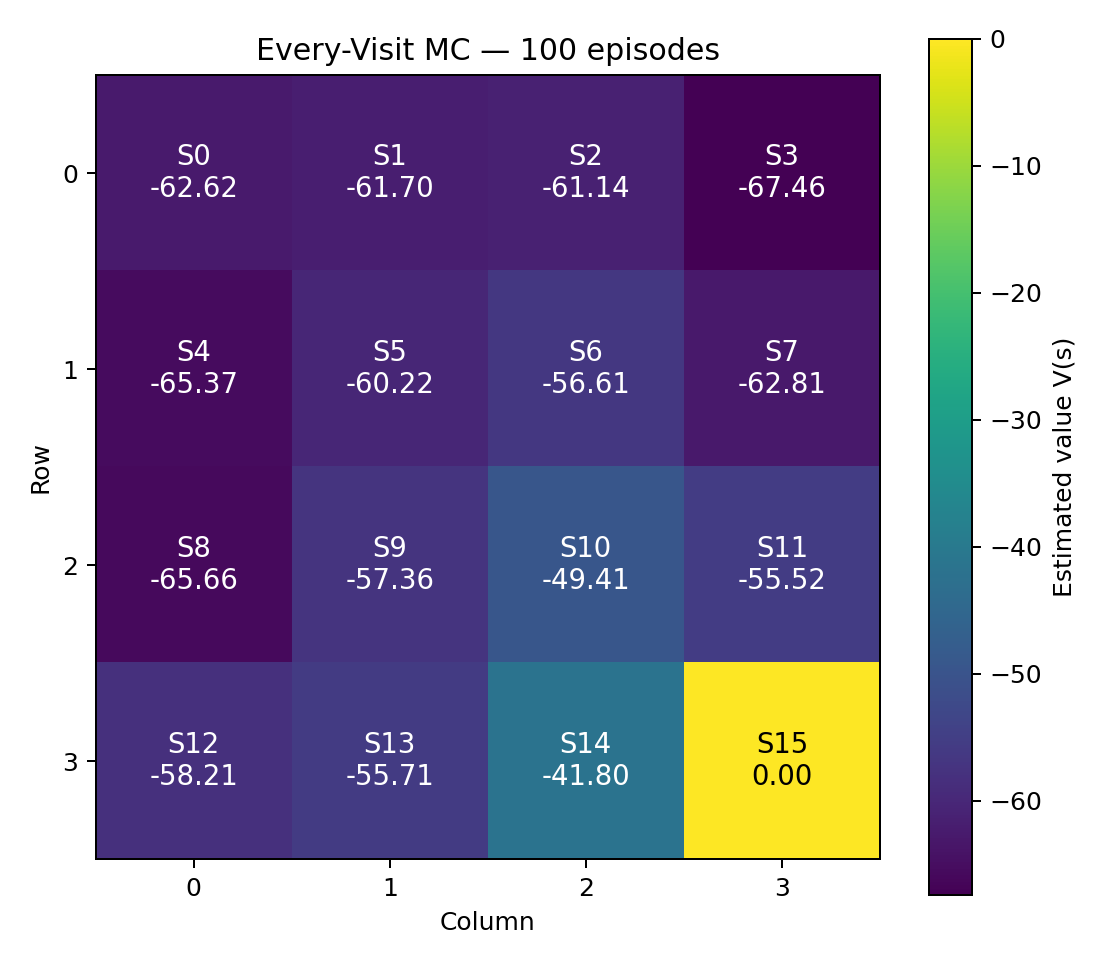

In [17]:
from pathlib import Path
from IPython.display import Image, display
from gridworld_rl.utils.output import format_value_grid, save_value_csv, save_value_image

print('[MC 100 episodes]')
print(format_value_grid(mc_demo.values))
save_value_csv(mc_demo.values, Path('results/demo_mc_values.csv'))
save_value_image(mc_demo.values, Path('results/demo_mc_values.png'), 'Every-Visit MC — 100 episodes')
assert Path('results/demo_mc_values.csv').exists()
assert Path('results/demo_mc_values.png').exists()
display(Image(filename='results/demo_mc_values.png'))


## 7. 명령행 인터페이스(CLI): `cli.py`와 `main.py`

이제 앞에서 만든 구성 요소를 연결합니다. CLI는 **명령 프롬프트/터미널에서 옵션을 붙여 프로그램을 실행하는 인터페이스**입니다. 예: `python main.py --algorithm td0 --episodes 50000 --alpha 0.01`.

### 7-1. `cli.py`를 직접 작성하는 순서

1. `argparse.ArgumentParser`를 만들고 실행 인수를 정의하는 `build_parser()` 작성.
2. `main(argv=None)`에서 `parse_args()`를 호출해 사용자가 입력한 명령행 옵션을 읽습니다.
3. 출력 폴더를 준비하고 `GridWorld()`를 **공통**으로 생성합니다.
4. `exact_uniform_policy_values()`로 검증용 기준값을 계산합니다.
5. `args.algorithm`이 `mc` 또는 `both`이면 MC를 학습하고, 4×4 값·MAE를 출력 목록에 추가하고 CSV/PNG를 저장합니다.
6. `td0` 또는 `both`이면 TD(0)를 마찬가지로 실행합니다.
7. 출력 목록을 줄바꿈으로 합쳐 화면과 `terminal_output.txt`에 함께 저장합니다.

**`argparse` 추가 개념:** `choices=(...)`는 허용 문자열만 받게 하고, `store_true`는 `--no-plot` 명령어가 있으면 True인 논리 플래그가 됩니다. `args.output_dir`는 `type=Path`를 사용했기 때문에 문자열이 아니라 `Path` 객체입니다.

**`if __name__ == '__main__'`**: `python cli.py`로 파일을 직접 실행하면 `main()`을 호출합니다. 다른 파일에서 `import`하는 경우에는 자동으로 학습이 시작되지 않게 합니다.


In [18]:
%%writefile src/gridworld_rl/cli.py
"""Run MC and/or TD(0), print values, and save screenshot-ready outputs."""

from __future__ import annotations

import argparse
from pathlib import Path

from gridworld_rl.agents import train_every_visit_mc, train_td0
from gridworld_rl.envs import GridWorld
from gridworld_rl.utils.analysis import exact_uniform_policy_values, mean_absolute_error
from gridworld_rl.utils.output import format_value_grid, save_value_csv, save_value_image


def build_parser() -> argparse.ArgumentParser:
    parser = argparse.ArgumentParser(description="HW3: 4x4 Grid World MC and TD(0)")
    parser.add_argument("--algorithm", choices=("mc", "td0", "both"), default="both")
    parser.add_argument("--episodes", type=int, default=50_000)
    parser.add_argument("--gamma", type=float, default=1.0)
    parser.add_argument("--alpha", type=float, default=0.01, help="TD(0) step size")
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--max-steps-per-episode", type=int, default=100_000)
    parser.add_argument("--output-dir", type=Path, default=Path("results"))
    parser.add_argument("--no-plot", action="store_true", help="Skip PNG export")
    return parser


def main(argv: list[str] | None = None) -> None:
    args = build_parser().parse_args(argv)
    args.output_dir.mkdir(parents=True, exist_ok=True)
    environment = GridWorld()
    reference = exact_uniform_policy_values(environment, gamma=args.gamma)

    output_lines = [
        "HW3 4x4 Grid World: uniform random actions, reward -1 per step, "
        "border actions remain in place (Lecture 2, p. 11)",
        f"episodes={args.episodes}, gamma={args.gamma}, seed={args.seed}",
    ]

    if args.algorithm in ("mc", "both"):
        mc = train_every_visit_mc(
            environment,
            episodes=args.episodes,
            gamma=args.gamma,
            seed=args.seed,
            max_steps_per_episode=args.max_steps_per_episode,
        )
        output_lines += [
            "", "[1-2] Every-Visit MC: V(s)",
            format_value_grid(mc.values),
            f"total_steps={mc.total_steps}, MAE_vs_exact={mean_absolute_error(mc.values, reference):.4f}",
        ]
        save_value_csv(mc.values, args.output_dir / "mc_values.csv")
        if not args.no_plot:
            save_value_image(mc.values, args.output_dir / "mc_values.png",
                             f"Every-Visit MC, {args.episodes:,} episodes")

    if args.algorithm in ("td0", "both"):
        td = train_td0(
            environment,
            episodes=args.episodes,
            gamma=args.gamma,
            alpha=args.alpha,
            seed=args.seed,
            max_steps_per_episode=args.max_steps_per_episode,
        )
        output_lines += [
            "", "[2-2] TD(0): V(s)",
            format_value_grid(td.values),
            f"alpha={td.alpha}, total_steps={td.total_steps}, "
            f"MAE_vs_exact={mean_absolute_error(td.values, reference):.4f}",
        ]
        save_value_csv(td.values, args.output_dir / "td0_values.csv")
        if not args.no_plot:
            save_value_image(td.values, args.output_dir / "td0_values.png",
                             f"TD(0), alpha={args.alpha}, {args.episodes:,} episodes")

    output_lines += ["", "[Reference] Exact Bellman-policy value (not learned)",
                     format_value_grid(reference)]
    save_value_csv(reference, args.output_dir / "exact_values.csv")
    report = "\n".join(output_lines) + "\n"
    print(report, end="")
    (args.output_dir / "terminal_output.txt").write_text(report, encoding="utf-8")
    print(f"Saved results to: {args.output_dir.resolve()}")


if __name__ == "__main__":
    main()


Writing src/gridworld_rl/cli.py


### 7-2. `main.py`: 실행을 쉽게 만드는 얇은 진입점

`main.py`는 중복 코드가 없습니다. 실제 실행 기능은 `gridworld_rl.cli.main()`에 모두 들어 있습니다. 사용자 관점에서는 `python main.py`만 입력해도 되게 만든 것입니다.


In [19]:
%%writefile main.py
"""Convenient entry point: python main.py --algorithm both --episodes 50000"""

from gridworld_rl.cli import main


if __name__ == "__main__":
    main()


Writing main.py


## 8. 설치·Git 설정 파일: `pyproject.toml`, `.gitignore`

**`pyproject.toml`**은 Python 프로젝트의 패키지 정보, 필요한 라이브러리, 설치·실행 진입점, 테스트 기본 설정을 표준 형태로 담습니다. 실무에서도 널리 사용하는 `src/` 기반 Python 패키지 방식입니다.

- `[build-system]`: 빌드 도구 `setuptools`를 정합니다.
- `[project]`: 패키지 이름, 버전, 최소 Python 버전, 런타임 의존성(torch, matplotlib)을 선언합니다.
- `[project.optional-dependencies]`의 `dev`: 개발·테스트에 필요한 pytest를 따로 관리합니다.
- `[project.scripts]`: 설치 뒤 `gridworld-hw3` 명령어로 CLI 함수를 실행할 수 있게 합니다.
- `[tool.setuptools.packages.find]`: `src/` 아래에서 실제 패키지를 찾게 합니다.
- `[tool.pytest.ini_options]`: 테스트 디렉터리를 지정합니다.

`pip install -e '.[dev]'`에서 `-e`는 **코드를 수정해도 재설치하지 않고 개발 중인 소스를 그대로 참조하는 편집 가능 설치(editable install)** 입니다. 실제 pip 설치는 아래에서 옵션으로만 안내하므로, 노트북을 실행한다고 자동 설치되지는 않습니다.

**`.gitignore`**는 `.pyc`, `__pycache__`, 노트북 체크포인트, 가상환경, 임시 테스트 폴더 등 Git에 올리지 않을 파일 패턴을 기록합니다. 한 번 프로젝트 루트에 만들면 하위 폴더에 같은 파일을 반복해서 만들 필요는 없습니다.


In [20]:
%%writefile pyproject.toml
[build-system]
requires = ["setuptools>=68", "wheel"]
build-backend = "setuptools.build_meta"

[project]
name = "gridworld-hw3-pytorch"
version = "0.1.0"
description = "Every-Visit Monte Carlo and TD(0) policy evaluation on a 4x4 Grid World"
requires-python = ">=3.10"
dependencies = [
    "torch>=2.4",
    "matplotlib>=3.7",
]

[project.optional-dependencies]
dev = ["pytest>=8"]

[project.scripts]
gridworld-hw3 = "gridworld_rl.cli:main"

[tool.setuptools.packages.find]
where = ["src"]

[tool.pytest.ini_options]
testpaths = ["tests"]


Writing pyproject.toml


In [21]:
%%writefile .gitignore
__pycache__/
*.py[cod]
.pytest_cache/
.mypy_cache/
.ruff_cache/
*.egg-info/
build/
dist/
.venv/
venv/
.ipynb_checkpoints/
.DS_Store


Writing .gitignore


In [22]:
%%writefile results/.gitkeep



Writing results/.gitkeep


## 9. 단위 테스트: 코드가 정확한지 자동으로 확인하기

프로젝트를 완성했다고 판단하기 전에 **각 동작을 입력과 기대값으로 검증**합니다. 테스트는 이미 구현한 코드의 결과를 확인하는 코드이므로, 원본 테스트 파일도 그대로 따라 작성합니다.

- `test_env.py`: 리셋, 벽에서 제자리 유지와 -1 보상, 목표 종료, 종료 후 행동 금지, 잘못된 행동 번호, 강의자료 경계 규칙.
- `test_agents.py`: Every-Visit 중복 방문, TD 계산, 정확한 벨만 해, MC/TD 재현성 및 동일 행동 횟수, 잘못된 파라미터, Lecture 2 p.14 정수 기준값.

**pytest 사용법:** `assert` 조건이 거짓이면 실패합니다. `pytest.raises(ValueError)`는 특정 오류가 발생해야 올바른 동작이라고 판정합니다. `pytest.approx`는 부동소수점 계산에 작은 오차가 있더라도 같은 결과로 인정하기 위해 사용합니다.

기본 테스트는 **10개**입니다. 50,000 에피소드를 모두 학습하지 않아도 중요한 로직을 먼저 확인하도록 짧은 횟수로 검증합니다.


In [23]:
%%writefile tests/test_env.py
import pytest

from gridworld_rl.envs import Action, GridWorld


def test_reset_and_wall_action():
    env = GridWorld()
    assert env.reset() == 0
    assert env.step(Action.UP) == (0, -1.0, False)
    assert env.step(Action.LEFT) == (0, -1.0, False)


def test_terminal_and_reset():
    env = GridWorld()
    for action in [Action.DOWN, Action.DOWN, Action.DOWN, Action.RIGHT,
                   Action.RIGHT, Action.RIGHT]:
        next_state, reward, done = env.step(action)
    assert (next_state, reward, done) == (15, -1.0, True)
    with pytest.raises(RuntimeError):
        env.step(Action.UP)
    assert env.reset() == 0
    assert env.done is False


def test_action_validation():
    env = GridWorld()
    with pytest.raises(ValueError):
        env.step(99)


def test_lecture2_wall_transitions_keep_position_with_minus_one_reward():
    """Lecture 2, p. 11: an impossible up move is still sampled and costs -1."""
    env = GridWorld()
    assert env.next_state(1, Action.UP) == 1
    assert env.next_state(3, Action.RIGHT) == 3
    assert env.next_state(12, Action.LEFT) == 12
    assert env.next_state(14, Action.DOWN) == 14
    env.state = 1
    assert env.step(Action.UP) == (1, -1.0, False)


Writing tests/test_env.py


In [24]:
%%writefile tests/test_agents.py
import torch
import pytest

from gridworld_rl.agents import train_every_visit_mc, train_td0
from gridworld_rl.agents.every_visit_mc import discounted_returns
from gridworld_rl.agents.td0 import td0_update
from gridworld_rl.envs import GridWorld
from gridworld_rl.utils.analysis import exact_uniform_policy_values


def test_returns_keep_every_occurrence():
    # If S0 occurs at both t=0 and t=2, its two returns are -3 and -1.
    states = torch.tensor([0, 1, 0])
    g = discounted_returns([-1, -1, -1], gamma=1.0)
    total = torch.zeros(2, dtype=torch.float64)
    total.index_add_(0, states, g)
    counts = torch.bincount(states, minlength=2)
    assert g.tolist() == [-3.0, -2.0, -1.0]
    assert float(total[0] / counts[0]) == -2.0
    assert int(counts[0]) == 2


def test_td_update_bootstrap_and_terminal():
    values = torch.tensor([0.0, -10.0, 0.0], dtype=torch.float64)
    td0_update(values, 0, -1.0, 1, False, alpha=0.5, gamma=1.0)
    assert float(values[0]) == -5.5  # 0 + 0.5*(-1 - 10 - 0)
    td0_update(values, 1, -1.0, 2, True, alpha=0.5, gamma=1.0)
    assert float(values[1]) == -5.5  # -10 + 0.5*(-1 - (-10))


def test_exact_solution_has_zero_terminal_value_and_bellman_equation():
    env = GridWorld()
    v = exact_uniform_policy_values(env, gamma=1.0)
    assert v.shape == (16,)
    assert v[-1].item() == 0.0
    assert torch.all(v[:-1] < 0)
    for state in range(15):
        expected = -1.0 + sum(float(v[env.next_state(state, action)])
                              for action in range(4)) / 4.0
        assert v[state].item() == pytest.approx(expected, abs=1e-10)


def test_both_algorithms_return_4_by_4_and_same_seed_reproducibly():
    env = GridWorld()
    a = train_every_visit_mc(env, episodes=100, seed=7)
    b = train_every_visit_mc(env, episodes=100, seed=7)
    assert torch.equal(a.values, b.values)
    assert torch.equal(a.visit_counts, b.visit_counts)
    assert a.values.shape == (16,)
    assert a.values[15] == 0
    assert a.total_steps == int(a.visit_counts.sum())
    td = train_td0(env, episodes=100, seed=7)
    assert td.values.shape == (16,)
    assert td.values[15] == 0
    assert td.total_steps == a.total_steps  # identical random paths
    assert int(td.visit_counts.sum()) == td.total_steps


def test_invalid_parameters():
    with pytest.raises(ValueError):
        train_every_visit_mc(GridWorld(), episodes=0)
    with pytest.raises(ValueError):
        train_td0(GridWorld(), alpha=0)


def test_lecture2_page14_one_terminal_reference_values():
    """Lecture 2, p. 14 matches the same single-terminal task as HW3."""
    expected_rounded = torch.tensor([
        [-59, -57, -54, -52],
        [-57, -55, -50, -45],
        [-54, -50, -41, -30],
        [-52, -45, -30, 0],
    ], dtype=torch.float64)
    actual = exact_uniform_policy_values(GridWorld()).reshape(4, 4)
    assert torch.equal(torch.round(actual), expected_rounded)


Writing tests/test_agents.py


### 9-1. 실제 테스트 실행하기

아래 셀은 **현재 노트북 커널과 같은 Python**으로 pytest를 실행합니다. `PYTHONPATH`에 방금 작성한 `src` 경로를 추가하므로, 따로 설치하지 않아도 테스트할 수 있습니다.


In [25]:
import subprocess
import os
import sys
from pathlib import Path

test_env = dict(os.environ)
test_env['PYTHONPATH'] = str((Path.cwd() / 'src').resolve()) + os.pathsep + test_env.get('PYTHONPATH', '')
run_tests = subprocess.run(
    [sys.executable, '-m', 'pytest', '-q', 'tests'],
    cwd=Path.cwd(), env=test_env, text=True, capture_output=True,
)
print(run_tests.stdout)
if run_tests.stderr:
    print(run_tests.stderr)
assert run_tests.returncode == 0, '테스트 실패: 위 오류를 확인하세요.'


..........                                                               [100%]
10 passed in 1.31s



## 10. 원본과 완전히 같은 코드인지 SHA-256으로 검증하기

원본 ZIP의 핵심 파일마다 **SHA-256 해시**를 미리 계산해 아래의 `EXPECTED_SHA256`에 넣었습니다. `SHA-256`은 파일 내용이 달라지면 해시값이 극히 높은 확률로 달라지는 방식이므로, 공백·주석·줄바꿈까지 포함하여 원본과 일치하는지 확인할 수 있습니다.

**주의:** 아래의 값은 *이번 Notebook의 기준으로 삼은 이전 제공 ZIP*(`gridworld-hw3-pytorch-verified-lecture2-3.zip`)의 원본 파일을 기준으로 계산했습니다. 사용자가 이해를 위해 일부러 코드를 수정한 경우에는 검증이 실패하는 것이 정상입니다.


In [26]:
import hashlib
from pathlib import Path

EXPECTED_SHA256 = {
    'src/gridworld_rl/__init__.py': '4ab83804a233b28e5ed4ffc91c3afa6193a955afaf9a944995964c1c848fc0fe',
    'src/gridworld_rl/envs/__init__.py': '699bc656413813c9b5550080bd389a6533ab83c305bc8dcd8b06e721fc6139bd',
    'src/gridworld_rl/envs/gridworld.py': '2a5f90766a2dfe51cbc1396f770238d8536ecc50bb08c7bcdbbe4f2577490a23',
    'src/gridworld_rl/agents/every_visit_mc.py': '27909197d5964fcd25dcfd1859b29295f91b207ac339e887b124284b45373891',
    'src/gridworld_rl/agents/td0.py': 'fa1178f78ec2e406aa1d69635de4bb6d53ea1760d492c8bfb1124c123570045b',
    'src/gridworld_rl/agents/__init__.py': '83cd059f785f8bb5a7a13778597a64b754b712631cb061670a98e3a5d7374581',
    'src/gridworld_rl/utils/__init__.py': 'd2d5934d7a72fa1f4de4d547528697f380aa82fb7bcd9deea89f46a5cc517e2d',
    'src/gridworld_rl/utils/analysis.py': '173fb8fee1c29164055db9ab7f3b0920aa51f4d19d3fde8d5266bf36048b06c6',
    'src/gridworld_rl/utils/output.py': 'b61f900a0cc86ef593e04c0dfb57bab1c1c0b8b395b17d7f77d1a9fa78e30e6b',
    'src/gridworld_rl/cli.py': 'ee5f064320e0a02bd0181cb1ee32311755261be5f36e7216851e630938bf0172',
    'main.py': '0a71330098c8bde172f75600a18f3fe55d23676b96a9e1d18ef357217b40c7ca',
    'pyproject.toml': 'b95b3ffb80d8a6a23b6f674ad06ebc9b1c92d5ba79ee504bb63b567ef33efcdc',
    '.gitignore': 'e6027cf5eff4db22b25d8250b2d61c61620b7afbcea1ce6044eca982e6ef37e7',
    'results/.gitkeep': '01ba4719c80b6fe911b091a7c05124b64eeece964e09c058ef8f9805daca546b',
    'tests/test_env.py': '32f364acee9388c7ea520022aad36962fd61cfd9d47287913359753c13457c9b',
    'tests/test_agents.py': 'e52083f29e94c531ee9a288af0b52ef124bb1842c576e2fc53970369b652323a',
}

mismatches = []
for relative_path, expected_digest in EXPECTED_SHA256.items():
    fpath = Path(relative_path)
    digest = hashlib.sha256(fpath.read_bytes()).hexdigest() if fpath.is_file() else '(파일 없음)'
    if digest != expected_digest:
        mismatches.append(relative_path)

print(f'원본 일치 파일: {len(EXPECTED_SHA256) - len(mismatches)}/{len(EXPECTED_SHA256)}')
if mismatches:
    for name in mismatches:
        print('내용 불일치:', name)
else:
    print('완료: 소스 코드, 테스트, 구성 파일이 제공한 원본 ZIP과 바이트 단위로 일치합니다.')
assert not mismatches, '원본과 다른 파일이 있습니다. 해당 %%writefile 셀을 다시 확인하세요.'


원본 일치 파일: 16/16
완료: 소스 코드, 테스트, 구성 파일이 제공한 원본 ZIP과 바이트 단위로 일치합니다.


## 11. `main.py`를 실제로 실행해 HW3 결과 파일 만들기

### 11-1. 먼저 빠른 시범 실행

아래 명령은 `--episodes 100`으로 **실행이 되는지**만 확인합니다. Python을 명시하고 `PYTHONPATH`를 지정하므로 별도의 패키지 설치가 필요하지 않습니다. 터미널에서 일반적으로 사용하려면 프로젝트 루트에서 `python -m pip install -e ".[dev]"`를 먼저 실행한 후 `python main.py`로 실행하면 됩니다.

`--output-dir results/quick_run`으로 저장하기 때문에 아래의 참고 결과나 다른 실험 파일을 덮어쓰지 않습니다.


In [27]:
import os
import subprocess
import sys
from pathlib import Path

root = Path.cwd()
cli_env = dict(os.environ)
cli_env['PYTHONPATH'] = str((root / 'src').resolve()) + os.pathsep + cli_env.get('PYTHONPATH', '')
cmd = [sys.executable, 'main.py', '--algorithm', 'both', '--episodes', '100',
       '--gamma', '1.0', '--alpha', '0.01', '--seed', '42',
       '--output-dir', 'results/quick_run']
print('실행 명령:', ' '.join(cmd))
run = subprocess.run(cmd, cwd=root, env=cli_env, text=True, capture_output=True)
print(run.stdout)
if run.stderr:
    print(run.stderr)
assert run.returncode == 0, 'main.py 실행에 실패했습니다.'
for name in ('mc_values.csv', 'td0_values.csv', 'exact_values.csv',
             'mc_values.png', 'td0_values.png', 'terminal_output.txt'):
    assert (root / 'results/quick_run' / name).is_file(), f'{name} 저장 실패'
print('CLI와 6개 출력 파일 확인 완료')


실행 명령: /opt/pyvenv/bin/python main.py --algorithm both --episodes 100 --gamma 1.0 --alpha 0.01 --seed 42 --output-dir results/quick_run


HW3 4x4 Grid World: uniform random actions, reward -1 per step, border actions remain in place (Lecture 2, p. 11)
episodes=100, gamma=1.0, seed=42

[1-2] Every-Visit MC: V(s)
  -56.291    -59.321    -57.659    -49.388
  -54.524    -57.813    -53.516    -43.182
  -60.157    -55.670    -51.625    -35.750
  -62.522    -42.422    -25.983      0.000
total_steps=6309, MAE_vs_exact=4.2832

[2-2] TD(0): V(s)
   -5.631     -5.114     -4.463     -4.005
   -4.993     -4.562     -3.996     -3.510
   -4.573     -4.054     -3.290     -2.286
   -4.004     -3.568     -1.934      0.000
alpha=0.01, total_steps=6309, MAE_vs_exact=41.9654

[Reference] Exact Bellman-policy value (not learned)
  -59.429    -57.429    -54.286    -51.714
  -57.429    -54.571    -49.714    -45.143
  -54.286    -49.714    -40.857    -30.000
  -51.714    -45.143    -30.000      0.000
Saved results to: /mnt/data/_notebook_build/execution/handwritten_gridworld_hw3/results/quick_run

CLI와 6개 출력 파일 확인 완료


### 11-2. 실제 이미지 두 장 표시하기

문항 1-2와 2-2는 **4×4 가치함수 결과**를 출력해 제출하는 과제입니다. 실제 50,000에피소드 값으로 제출하려면 **아래 11-3 셀에서 전체 학습을 켜야** 합니다. 지금 표시되는 두 그림은 빠른 실행 결과입니다.


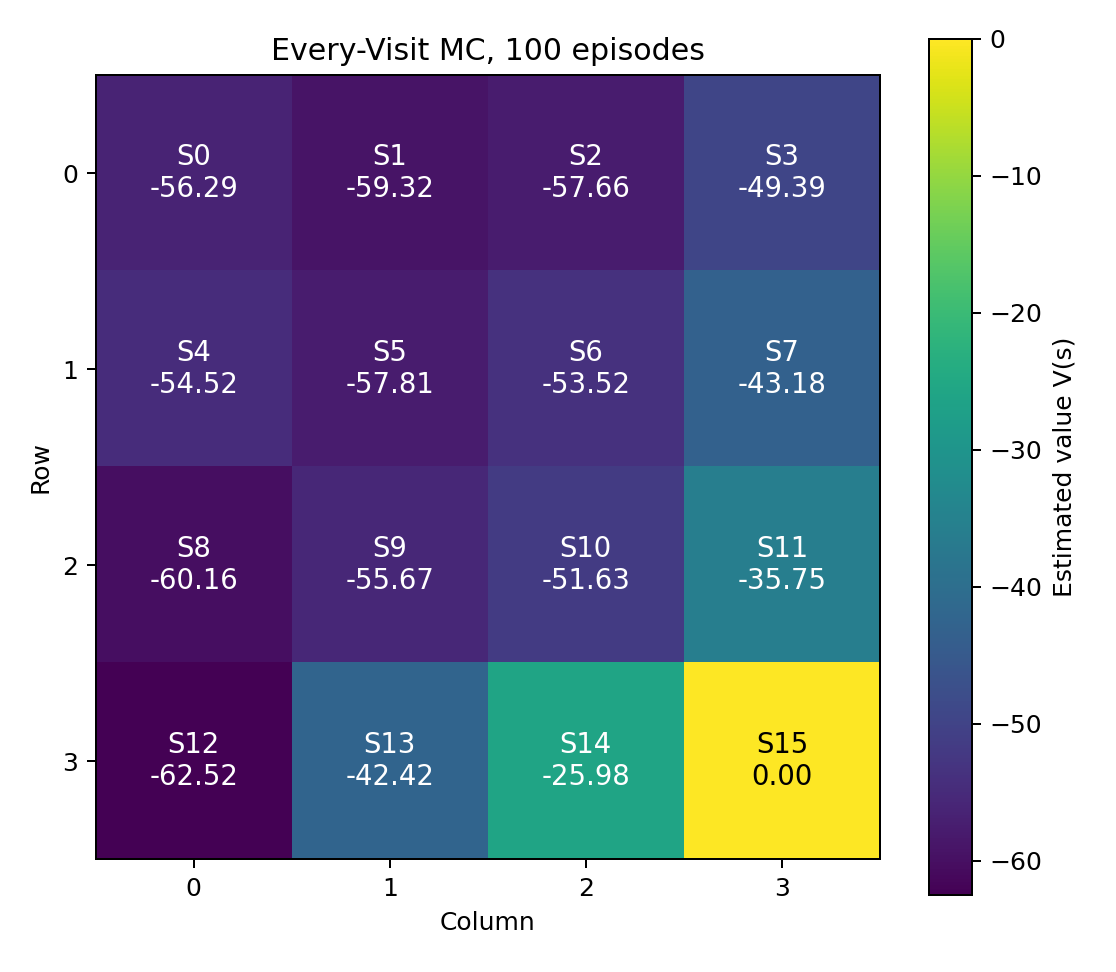

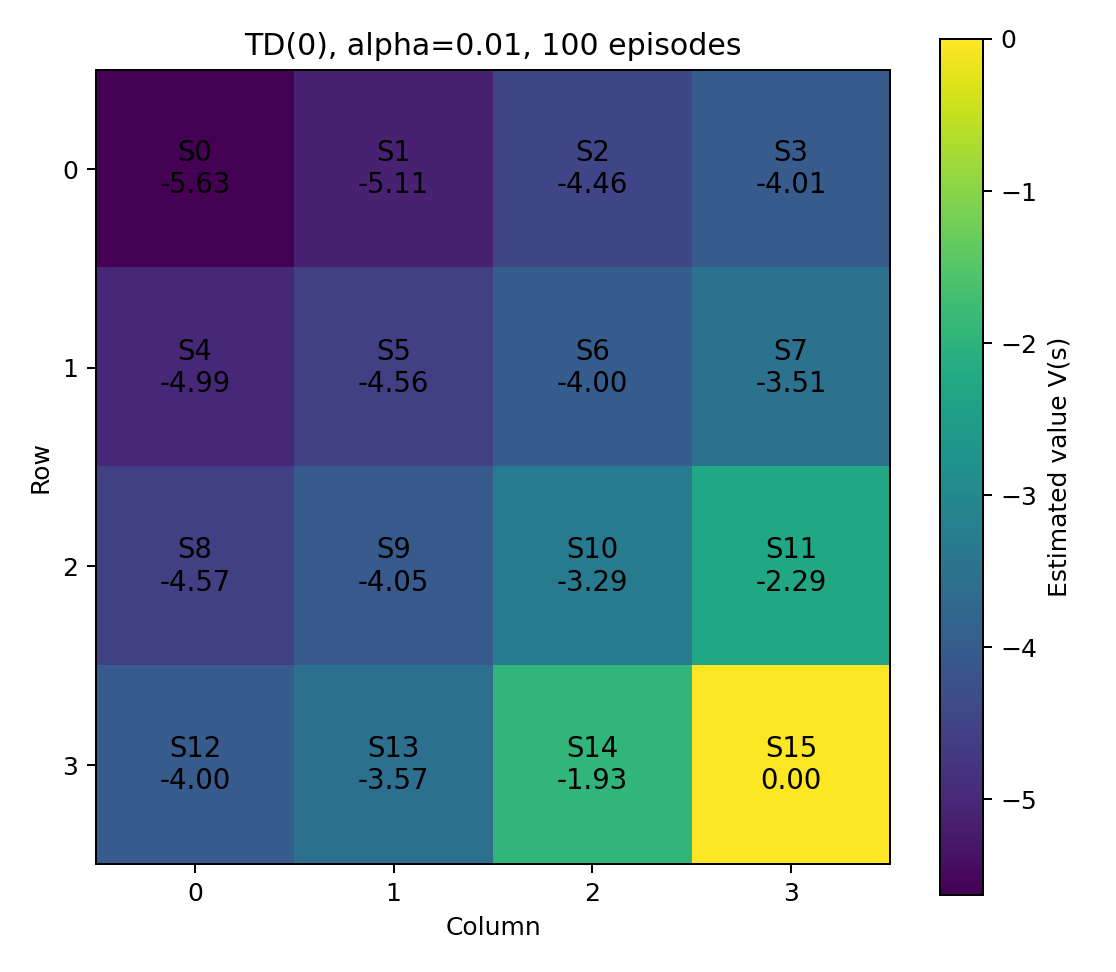

In [28]:
from IPython.display import display, Image

display(Image(filename='results/quick_run/mc_values.png'))
display(Image(filename='results/quick_run/td0_values.png'))


### 11-3. 과제 조건의 50,000에피소드 전체 실행 (선택)

**여기서는 사용자가 직접 의도를 확인하도록 기본값을 `False`로 둡니다.** `RUN_FULL_TRAINING = True`로 바꾸면 MC와 TD가 각각 50,000개의 에피소드를 학습하며, 수백만 번의 상태 전이를 진행하므로 빠른 실습보다 오래 걸립니다. 시드와 학습률 등 원본과 같은 값을 사용합니다.

완료되면 `results/full_run/`에 `mc_values.png`, `td0_values.png`, 3개 CSV, `terminal_output.txt`가 생성됩니다. 캡처 또는 보고서에는 **이 디렉터리의 결과**를 쓰세요.


In [29]:
RUN_FULL_TRAINING = False  # 과제 최종 결과가 필요할 때 True로 변경

if RUN_FULL_TRAINING:
    full_cmd = [sys.executable, 'main.py', '--algorithm', 'both',
                '--episodes', '50000', '--gamma', '1.0', '--alpha', '0.01',
                '--seed', '42', '--output-dir', 'results/full_run']
    full_run = subprocess.run(full_cmd, cwd=Path.cwd(), env=cli_env,
                              text=True, capture_output=True)
    print(full_run.stdout)
    if full_run.stderr:
        print(full_run.stderr)
    assert full_run.returncode == 0
    display(Image(filename='results/full_run/mc_values.png'))
    display(Image(filename='results/full_run/td0_values.png'))
else:
    print('전체 실행은 생략되었습니다. 과제 결과를 만들려면 RUN_FULL_TRAINING=True로 설정하세요.')


전체 실행은 생략되었습니다. 과제 결과를 만들려면 RUN_FULL_TRAINING=True로 설정하세요.


### 11-4. 원본 프로젝트의 50,000에피소드 결과 (수치 대조용)

아래는 **기존 ZIP에 보관된** `seed=42`, MC·TD 각각 50,000에피소드 실행 로그입니다. 본 Notebook을 짧게 실행한 결과가 아닙니다. 환경·난수 구현과 소스 파일이 완전히 같고 동일한 Python 난수 순서를 사용한다면, 전체 실행 결과도 이 수치와 일치해야 합니다(파이썬·PyTorch 버전 및 플랫폼에 따른 미세한 부동소수점 표시는 달라질 수 있습니다).

```text
[1-2] Every-Visit MC: V(s)
  -59.242    -57.198    -54.278    -52.022
  -57.201    -54.364    -49.552    -45.504
  -54.093    -49.578    -40.595    -30.173
  -51.599    -45.055    -29.924      0.000
total_steps=2979871, MAE_vs_exact=0.1708

[2-2] TD(0): V(s)
  -57.637    -55.497    -52.808    -49.939
  -55.580    -52.254    -47.302    -41.932
  -52.080    -47.224    -38.024    -29.106
  -49.773    -43.790    -27.641      0.000
alpha=0.01, total_steps=2979871, MAE_vs_exact=1.9276

[Reference] Exact Bellman-policy value (not learned)
  -59.429    -57.429    -54.286    -51.714
  -57.429    -54.571    -49.714    -45.143
  -54.286    -49.714    -40.857    -30.000
  -51.714    -45.143    -30.000      0.000
```

MC의 오차가 이 실행에서는 TD보다 작지만 **MC가 항상 TD보다 우수하다는 의미는 아닙니다.** 학습률, 무작위 경로, 에피소드 수, 관측된 경험에 따라 결과가 달라지므로, 관측 결과와 일반적 성능에 관한 결론을 구별해야 합니다.


## 12. HW3 2-3 답안 준비 — 알고리즘의 차이를 직접 서술해 보기

| 비교 | Every-Visit MC | TD(0) |
|---|---|---|
| 무엇을 이용해 갱신하나? | 해당 상태 방문 시점부터 **에피소드가 끝날 때까지 관측한 실제 보상 총합** | 바로 다음 행동의 보상과 **다음 상태의 현재 가치 추정값** |
| 업데이트 시점 | 각 에피소드 종료 **후** | 각 행동·전이 **직후** |
| 하나의 에피소드 안에서 같은 상태를 여러 번 방문하면? | 모든 방문의 반환값을 각각 누적·평균 | 방문할 때마다 현재 가치에 새로운 한 단계 오차를 적용 |
| 추정값을 다음 갱신에 재사용하는가? | 반환값 계산에는 사용하지 않음 | 다음 상태의 추정값을 사용함 |
| 이번 코드의 학습률 | 관측값 평균: 방문 횟수에 따라 반영 크기가 자연히 감소 | 고정 `alpha=0.01` |
| 에피소드 종료가 필요한가? | 전체 반환값을 알려면 필요 | 각 행동 직후 업데이트 가능 |

**과제 보고서의 논리 순서:** (1) 공통 환경·정책을 설명 → (2) MC 갱신 기준과 시점 → (3) TD 갱신 기준과 시점 → (4) 실제 값을 비교 → (5) 한 번의 결과에서 일반적인 우열은 확정할 수 없다고 명시.

**학습 점검 질문(직접 답해보기)**

1. `states.append(env.state)`는 왜 `env.step(action)` **앞**에 있는가?
2. MC 반환값을 뒤에서부터 계산하면 어떤 중복 연산을 없앨 수 있는가?
3. `index_add_`를 일반적인 `values[state_ids] += returns`로 단순 치환하면 중복 상태 번호를 어떻게 잘못 처리할 위험이 있는가?
4. MC의 `visit_counts`와 TD의 `visit_counts`는 각각 **언제** 증가하는가?
5. S15의 값이 왜 0이어야 하는가? S15에 도착하는 행동에는 왜 -1 보상이 있는가?
6. `next_state`는 왜 환경 상태를 바꾸지 않는 별도 함수인가?
7. `exact_uniform_policy_values`는 왜 16×16이 아닌 15×15 행렬을 푸는가?
8. 두 알고리즘의 `total_steps`가 같은 이유는 무엇인가? 두 알고리즘의 가치가 다른 이유는 무엇인가?
9. `frozen=True`가 텐서 내용을 수정할 수 없게 만드는가?
10. **동일한 소스 코드 작성**과 **학습 결과의 수치적 일치**는 왜 구별해야 하는가?

위 질문에 코드 줄을 짚으며 답할 수 있다면 기능을 단순히 외운 것보다 확실히 이해한 것입니다.


## 13. 스스로 다시 작성하기 위한 최종 체크리스트

- [ ] 4×4 상태 번호를 행·열로 바꾸고 경계 처리를 작성할 수 있다.
- [ ] `GridWorld.reset()`, `next_state()`, `step()`의 차이를 설명할 수 있다.
- [ ] `dataclass`, `field(init=False)`, `__post_init__`, `IntEnum`, `@property`, `__future__`를 설명할 수 있다.
- [ ] MC의 에피소드 기록, 역순 반환값, 모든 방문의 평균을 구현할 수 있다.
- [ ] `torch.index_add_`, `torch.bincount`, bool mask의 목적을 설명할 수 있다.
- [ ] TD의 한 단계 갱신과 종료 상태 보정을 구현할 수 있다.
- [ ] 정확한 벨만 기준값과 정책 학습값을 구별할 수 있다.
- [ ] 출력 유틸, CLI, 테스트, 패키징 파일의 역할을 설명할 수 있다.
- [ ] `main.py --episodes 50000`을 실행하여 과제 문항의 그림과 값을 저장할 수 있다.
- [ ] 위 질문들을 소스 파일을 보지 않고 순서대로 다시 구현해 설명할 수 있다.

**처음부터 다시 손으로 써 보려면:** 지금 만든 `handwritten_gridworld_hw3/`를 다른 이름으로 백업한 후 Notebook을 새 커널에서 다시 실행하거나, 새 폴더에서 노트북을 실행하세요. 원본 제공 ZIP은 변경되지 않습니다.

**참고 — 설치 후 터미널 실행:** 프로젝트 루트에서 아래와 같이 실행합니다.

```bash
python -m pip install -e ".[dev]"
python main.py --algorithm both --episodes 50000 --gamma 1.0 --alpha 0.01 --seed 42
python -m pytest -q tests
```

Notebook을 HTML로 저장하려면 Notebook을 저장한 뒤 터미널에서 `jupyter nbconvert --to html gridworld_hw3_완전구현_따라쓰기_튜토리얼.ipynb` 명령어를 사용할 수 있습니다.
